# Computer Vision Assignment 2
### Self-Supervised Learning for Image Classification

Comparison of supervised and self-supervised learning methods using 2,400 training images across 16 classes.

## 1. GPU Verification

Verifying GPU availability for model training.

In [2]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU: Tesla T4


## 2. Dataset Upload and Extraction

Upload and extract the training and test datasets for image classification.

In [3]:
from google.colab import files
import os

required_files = ["train.zip", "test.zip"]

missing_files = [
    name for name in required_files
    if not os.path.exists(f"/content/{name}")
]

if missing_files:
    print("Please upload:", missing_files)
    uploaded = files.upload()
else:
    print("Both ZIP files are already uploaded. Skipping upload.")

Both ZIP files are already uploaded. Skipping upload.


In [6]:
import os
import zipfile

DATA_DIR = "/content/dataset"
os.makedirs(DATA_DIR, exist_ok=True)

for filename in ["train.zip", "test.zip"]:
    zip_path = f"/content/{filename}"

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

    print(f"{filename} extracted successfully!")

train.zip extracted successfully!
test.zip extracted successfully!


In [7]:
for root, dirs, files in os.walk(DATA_DIR):
    print(root, "->", len(files), "files")

/content/dataset -> 0 files
/content/dataset/test -> 0 files
/content/dataset/test/Industrial -> 25 files
/content/dataset/test/OpenCountry -> 25 files
/content/dataset/test/InsideCity -> 25 files
/content/dataset/test/Office -> 25 files
/content/dataset/test/LivingRoom -> 25 files
/content/dataset/test/Forest -> 25 files
/content/dataset/test/TallBuilding -> 25 files
/content/dataset/test/Street -> 25 files
/content/dataset/test/Bedroom -> 25 files
/content/dataset/test/Suburb -> 25 files
/content/dataset/test/Highway -> 25 files
/content/dataset/test/Store -> 25 files
/content/dataset/test/Coast -> 25 files
/content/dataset/test/Flower -> 25 files
/content/dataset/test/Mountain -> 25 files
/content/dataset/test/Kitchen -> 25 files
/content/dataset/train -> 1 files
/content/dataset/train/Industrial -> 150 files
/content/dataset/train/OpenCountry -> 150 files
/content/dataset/train/InsideCity -> 150 files
/content/dataset/train/Office -> 150 files
/content/dataset/train/LivingRoom -> 1

## 3. Dataset Preparation

Splitting the training images into 80% for training and 20% for validation. Using the same split for all the experiments to compare the models fairly.

In [8]:
import numpy as np
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from collections import Counter

train_dir = "/content/dataset/train"
test_dir = "/content/dataset/test"

train_dataset = ImageFolder(train_dir)
test_dataset = ImageFolder(test_dir)

labels = np.array(train_dataset.targets)
indices = np.arange(len(train_dataset))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=labels,
    random_state=42
)

print("Classes:", len(train_dataset.classes))
print("Total training images:", len(train_dataset))
print("Training split:", len(train_idx))
print("Validation split:", len(val_idx))
print("Test images:", len(test_dataset))

assert train_dataset.classes == test_dataset.classes, "Class labels do not match!"
assert set(train_idx).isdisjoint(set(val_idx)), "Training and validation overlap!"

Classes: 16
Total training images: 2400
Training split: 1920
Validation split: 480
Test images: 400


## 4. Common Image Settings

Setting the image size, batch size, and normalization values used across all experiments.

In [9]:
from torchvision import transforms

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 16

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: 224
Batch size: 32
Number of classes: 16


## 5. Experiment 1: ConvNeXt-Atto (Supervised)

Training a ConvNeXt-Atto model from scratch using labeled images and evaluating its classification accuracy.

### 5.1 Data Augmentation and Data Loaders

Applying random changes to training images to reduce overfitting. Keeping the validation and test images unchanged.

In [10]:
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset

# Experiment 1 training augmentation
exp1_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# Creating datasets
exp1_train_dataset = ImageFolder(
    train_dir,
    transform=exp1_train_transform
)

exp1_val_dataset = ImageFolder(
    train_dir,
    transform=eval_transform
)

exp1_test_dataset = ImageFolder(
    test_dir,
    transform=eval_transform
)

# Creating data loaders
exp1_train_loader = DataLoader(
    Subset(exp1_train_dataset, train_idx),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

exp1_val_loader = DataLoader(
    Subset(exp1_val_dataset, val_idx),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

exp1_test_loader = DataLoader(
    exp1_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(exp1_train_loader))
print("Validation batches:", len(exp1_val_loader))
print("Testing batches:", len(exp1_test_loader))

Training batches: 60
Validation batches: 15
Testing batches: 13


In [11]:
exp1_val_transform = eval_transform

### 5.2 ConvNeXt-Atto Training and Evaluation

Train ConvNeXt-Atto from scratch, select the best model using validation accuracy, and measure its test accuracy.

In [ ]:
!pip -q install timm

import timm
import torch
import torch.nn as nn
import numpy as np
import time
import copy
import os

from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Hyperparameters
EPOCHS = 30
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.05
PATIENCE = 7

# Initialize model from scratch
model = timm.create_model(
    "convnext_atto",
    pretrained=False,
    num_classes=NUM_CLASSES
).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

best_val_acc = 0.0
best_weights = copy.deepcopy(model.state_dict())
patience_counter = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

for epoch in range(EPOCHS):

    # Training
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in exp1_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = 100 * train_correct / train_total

    # Validation
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in exp1_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = 100 * val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    scheduler.step()

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

    # Save best model based on validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model.state_dict())
        torch.save(best_weights, "exp1_convnext_atto_best.pth")
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

training_time = time.time() - start_time

model.load_state_dict(best_weights)

print(f"\nBest Validation Accuracy: {best_val_acc:.2f}%")
print(f"Training Time: {training_time/60:.2f} minutes")

Epoch 1/30 | Train Loss: 2.7155 | Train Acc: 13.39% | Val Loss: 2.6418 | Val Acc: 15.83%
Epoch 2/30 | Train Loss: 2.5529 | Train Acc: 18.70% | Val Loss: 2.4818 | Val Acc: 22.92%
Epoch 3/30 | Train Loss: 2.4670 | Train Acc: 21.67% | Val Loss: 2.3795 | Val Acc: 28.33%
Epoch 4/30 | Train Loss: 2.3967 | Train Acc: 24.22% | Val Loss: 2.3247 | Val Acc: 27.92%
Epoch 5/30 | Train Loss: 2.3007 | Train Acc: 29.06% | Val Loss: 2.2007 | Val Acc: 31.46%
Epoch 6/30 | Train Loss: 2.1930 | Train Acc: 33.23% | Val Loss: 2.1905 | Val Acc: 32.08%
Epoch 7/30 | Train Loss: 2.1351 | Train Acc: 34.69% | Val Loss: 2.1311 | Val Acc: 35.21%
Epoch 8/30 | Train Loss: 2.1143 | Train Acc: 35.62% | Val Loss: 2.0682 | Val Acc: 37.29%
Epoch 9/30 | Train Loss: 2.0553 | Train Acc: 37.45% | Val Loss: 2.0393 | Val Acc: 38.12%
Epoch 10/30 | Train Loss: 2.0017 | Train Acc: 41.09% | Val Loss: 2.0118 | Val Acc: 39.17%
Epoch 11/30 | Train Loss: 1.9660 | Train Acc: 41.35% | Val Loss: 1.9987 | Val Acc: 40.42%
Epoch 12/30 | Train

Best Validation Accuracy: 56.04%
Test Accuracy: 54.25%
Training Time: 6.42 minutes


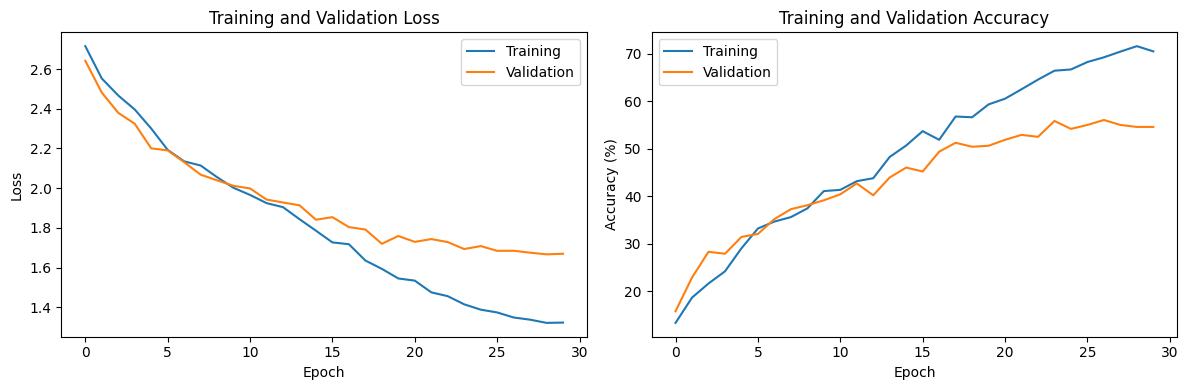

,Experiment,Architecture + Method,Validation Accuracy (%),Test Accuracy (%)
0,E1,ConvNeXt-Atto (Supervised),56.04,54.25


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# Test evaluation
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in exp1_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        test_correct += (outputs.argmax(1) == labels).sum().item()
        test_total += labels.size(0)

test_acc = 100 * test_correct / test_total

print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Training Time: {training_time/60:.2f} minutes")

# Training graphs
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training")
plt.plot(val_accuracies, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("exp1_training_curves.png", dpi=150)
plt.show()

# Experiment results
results = pd.DataFrame([{
    "Experiment": "E1",
    "Architecture + Method": "ConvNeXt-Atto (Supervised)",
    "Validation Accuracy (%)": round(best_val_acc, 2),
    "Test Accuracy (%)": round(test_acc, 2)
}])

display(results)

results.to_csv("experiment_results.csv", index=False)

# Download results and checkpoint
files.download("exp1_convnext_atto_best.pth")
files.download("experiment_results.csv")
files.download("exp1_training_curves.png")

### 5.3 Test Evaluation and Results

Evaluating the checkpoint with the highest validation accuracy on the test dataset and saving the results.

In [ ]:
from google.colab import files
import os

files_to_download = [
    "exp1_convnext_atto_best.pth",
    "exp1_training_curves.png",
    "experiment_results.csv"
]

for filename in files_to_download:
    if os.path.exists(filename):
        print(f"Downloading: {filename}")
        files.download(filename)
    else:
        print(f"File not found: {filename}")

Downloading: exp1_convnext_atto_best.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: exp1_training_curves.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: experiment_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Experiment 2: ConvNeXt-Atto + SimCLR

Use SimCLR to learn image features without labels, then fine-tune ConvNeXt-Atto for image classification.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import numpy as np
import random
import time

from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader, Subset
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# SimCLR settings
SSL_EPOCHS = 30
SSL_LR = 0.0003
SSL_WEIGHT_DECAY = 0.0001
TEMPERATURE = 0.2
SSL_BATCH_SIZE = 64

# SimCLR uses two different augmented views of the same image
simclr_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([
        transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)
    ], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

class SimCLRDataset(Dataset):
    def __init__(self, dataset, indices, transform):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image, _ = self.dataset[self.indices[idx]]
        return self.transform(image), self.transform(image)

ssl_base = ImageFolder(train_dir)

ssl_dataset = SimCLRDataset(
    ssl_base, train_idx, simclr_transform
)

ssl_loader = DataLoader(
    ssl_dataset,
    batch_size=SSL_BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

# ConvNeXt-Atto encoder initialized from scratch
encoder = timm.create_model(
    "convnext_atto",
    pretrained=False,
    num_classes=0
).to(device)

feature_dim = encoder.num_features

# Projection head for contrastive learning
projector = nn.Sequential(
    nn.Linear(feature_dim, 512),
    nn.ReLU(),
    nn.Linear(512, 128)
).to(device)

# NT-Xent contrastive loss
def simclr_loss(z1, z2, temperature=0.2):
    z = F.normalize(torch.cat([z1, z2], dim=0), dim=1)

    batch_size = z1.size(0)
    similarity = torch.matmul(z, z.T) / temperature

    mask = torch.eye(2 * batch_size, device=z.device).bool()
    similarity.masked_fill_(mask, -1e9)

    targets = torch.cat([
        torch.arange(batch_size, 2 * batch_size, device=z.device),
        torch.arange(batch_size, device=z.device)
    ])

    return F.cross_entropy(similarity, targets)

ssl_optimizer = AdamW(
    list(encoder.parameters()) + list(projector.parameters()),
    lr=SSL_LR,
    weight_decay=SSL_WEIGHT_DECAY
)

ssl_scheduler = CosineAnnealingLR(
    ssl_optimizer,
    T_max=SSL_EPOCHS
)

ssl_losses = []
ssl_start = time.time()

print("Starting SimCLR pretraining...")

for epoch in range(SSL_EPOCHS):
    encoder.train()
    projector.train()

    total_loss = 0

    for view1, view2 in ssl_loader:
        view1 = view1.to(device)
        view2 = view2.to(device)

        ssl_optimizer.zero_grad()

        features1 = encoder(view1)
        features2 = encoder(view2)

        z1 = projector(features1)
        z2 = projector(features2)

        loss = simclr_loss(z1, z2, TEMPERATURE)

        loss.backward()
        ssl_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(ssl_loader)
    ssl_losses.append(avg_loss)
    ssl_scheduler.step()

    print(f"SSL Epoch {epoch+1}/{SSL_EPOCHS} | Loss: {avg_loss:.4f}")

ssl_time = time.time() - ssl_start

print(f"\nSimCLR Pretraining Completed in {ssl_time/60:.2f} minutes")

torch.save(
    encoder.state_dict(),
    "exp2_simclr_pretrained_encoder.pth"
)

Starting SimCLR pretraining...
SSL Epoch 1/30 | Loss: 4.5931
SSL Epoch 2/30 | Loss: 4.3964
SSL Epoch 3/30 | Loss: 4.1153
SSL Epoch 4/30 | Loss: 3.9825
SSL Epoch 5/30 | Loss: 3.9409
SSL Epoch 6/30 | Loss: 3.7936
SSL Epoch 7/30 | Loss: 3.6592
SSL Epoch 8/30 | Loss: 3.3111
SSL Epoch 9/30 | Loss: 2.9284
SSL Epoch 10/30 | Loss: 2.7082
SSL Epoch 11/30 | Loss: 2.6097
SSL Epoch 12/30 | Loss: 2.5069
SSL Epoch 13/30 | Loss: 2.4704
SSL Epoch 14/30 | Loss: 2.4315
SSL Epoch 15/30 | Loss: 2.3688
SSL Epoch 16/30 | Loss: 2.3243
SSL Epoch 17/30 | Loss: 2.2895
SSL Epoch 18/30 | Loss: 2.2761
SSL Epoch 19/30 | Loss: 2.2077
SSL Epoch 20/30 | Loss: 2.2068
SSL Epoch 21/30 | Loss: 2.1420
SSL Epoch 22/30 | Loss: 2.1414
SSL Epoch 23/30 | Loss: 2.1110
SSL Epoch 24/30 | Loss: 2.1508
SSL Epoch 25/30 | Loss: 2.1139
SSL Epoch 26/30 | Loss: 2.0952
SSL Epoch 27/30 | Loss: 2.0779
SSL Epoch 28/30 | Loss: 2.0894
SSL Epoch 29/30 | Loss: 2.0710
SSL Epoch 30/30 | Loss: 2.0704

SimCLR Pretraining Completed in 10.75 minutes


### 6.2 Fine-Tuning and Validation

Fine-tuning the SimCLR model using labeled images and select the best model based on validation accuracy.

In [ ]:
import copy
import matplotlib.pyplot as plt
import pandas as pd

# Fine-tuning settings
FT_EPOCHS = 30
FT_LR = 0.0003
FT_WEIGHT_DECAY = 0.05
FT_PATIENCE = 7

# Create classification model
exp2_model = timm.create_model(
    "convnext_atto",
    pretrained=False,
    num_classes=NUM_CLASSES
).to(device)

# Load SimCLR pretrained encoder weights
load_result = exp2_model.load_state_dict(
    encoder.state_dict(),
    strict=False
)

print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = AdamW(
    exp2_model.parameters(),
    lr=FT_LR,
    weight_decay=FT_WEIGHT_DECAY
)

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=FT_EPOCHS
)

best_val_acc_exp2 = -1
best_epoch_exp2 = 0
patience_counter = 0

exp2_train_losses = []
exp2_val_losses = []
exp2_train_accs = []
exp2_val_accs = []

ft_start = time.time()

for epoch in range(FT_EPOCHS):

    # Training
    exp2_model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in exp1_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = exp2_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = 100 * train_correct / train_total

    # Validation
    exp2_model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in exp1_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = exp2_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = 100 * val_correct / val_total

    exp2_train_losses.append(train_loss)
    exp2_val_losses.append(val_loss)
    exp2_train_accs.append(train_acc)
    exp2_val_accs.append(val_acc)

    scheduler.step()

    print(
        f"Epoch {epoch+1}/{FT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

    # Save best model using validation accuracy
    if val_acc > best_val_acc_exp2:
        best_val_acc_exp2 = val_acc
        best_epoch_exp2 = epoch + 1

        torch.save(
            exp2_model.state_dict(),
            "exp2_simclr_best.pth"
        )

        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= FT_PATIENCE:
        print("Early stopping triggered.")
        break

ft_time = time.time() - ft_start

print("\nExperiment 2 — Validation Results")
print(f"Best Epoch: {best_epoch_exp2}")
print(f"Best Validation Accuracy: {best_val_acc_exp2:.2f}%")
print(f"Fine-Tuning Time: {ft_time/60:.2f} minutes")

NameError: name 'timm' is not defined

### 6.3 Test Evaluation and Results

Evaluating the checkpoint with the highest validation accuracy and saving the experiment results.


Experiment 2 — Final Results
Best Epoch: 29
Validation Accuracy: 67.08%
Test Accuracy: 63.25%
Total Training Time: 17.26 minutes


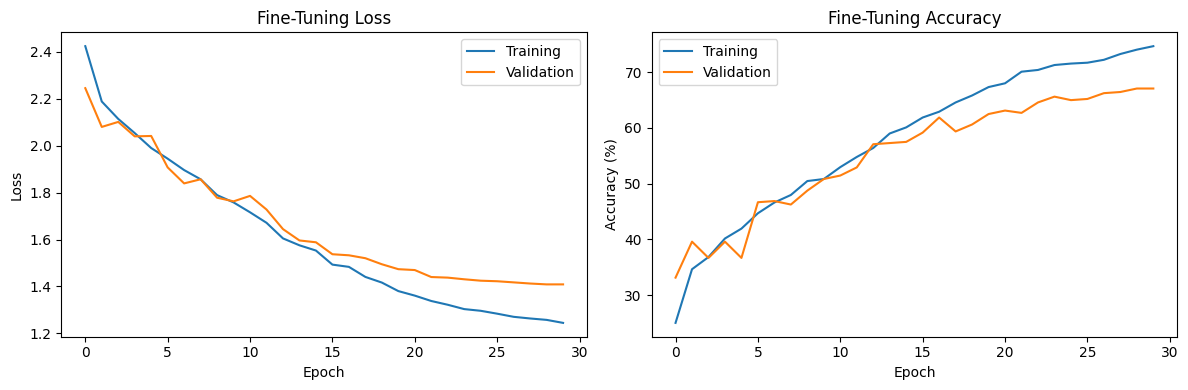

,Experiment,Architecture + Method,Validation Accuracy (%),Test Accuracy (%)
0,E1,ConvNeXt-Atto (Supervised),56.04,54.25
1,E2,ConvNeXt-Atto + SimCLR,67.08,63.25


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

# Load best validation checkpoint
exp2_model.load_state_dict(
    torch.load(
        "exp2_simclr_best.pth",
        map_location=device,
        weights_only=True
    )
)

# Test evaluation
exp2_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in exp1_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = exp2_model(images)

        test_correct += (outputs.argmax(1) == labels).sum().item()
        test_total += labels.size(0)

exp2_test_acc = 100 * test_correct / test_total

print("\nExperiment 2 — Final Results")
print(f"Best Epoch: {best_epoch_exp2}")
print(f"Validation Accuracy: {best_val_acc_exp2:.2f}%")
print(f"Test Accuracy: {exp2_test_acc:.2f}%")
print(f"Total Training Time: {(ssl_time + ft_time)/60:.2f} minutes")

# Training graphs
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(exp2_train_losses, label="Training")
plt.plot(exp2_val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-Tuning Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(exp2_train_accs, label="Training")
plt.plot(exp2_val_accs, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Fine-Tuning Accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("exp2_training_curves.png", dpi=150)
plt.show()

# Update experiment comparison table
results = pd.read_csv("experiment_results.csv")

results = results[results["Experiment"] != "E2"]

results = pd.concat([
    results,
    pd.DataFrame([{
        "Experiment": "E2",
        "Architecture + Method": "ConvNeXt-Atto + SimCLR",
        "Validation Accuracy (%)": round(best_val_acc_exp2, 2),
        "Test Accuracy (%)": round(exp2_test_acc, 2)
    }])
], ignore_index=True)

display(results)

results.to_csv("experiment_results.csv", index=False)

# Download results
files.download("exp2_simclr_best.pth")
files.download("exp2_training_curves.png")
files.download("experiment_results.csv")

## 7. Experiment 3: Joint SimCLR + Supervised Classification

Training ConvNeXt-Atto using self-supervised contrastive learning and supervised classification simultaneously. Comparing joint training with the supervised baseline and SimCLR pretraining followed by fine-tuning.

### 7.1 Joint SSL and Classification Training

Using two augmented views of each training image. Optimizing the SimCLR contrastive loss and classification loss together using a shared ConvNeXt-Atto encoder.

In [ ]:
import os
import time
import copy
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

# Experiment 3 settings
E3_EPOCHS = 35
E3_BATCH_SIZE = 32
E3_LR = 0.0003
E3_WEIGHT_DECAY = 0.05
E3_TEMPERATURE = 0.2
E3_SSL_WEIGHT = 0.1
E3_PATIENCE = 10
E3_CHECKPOINT = "/content/exp3_joint_simclr_best.pth"

# Use the same training split as previous experiments
base_dataset_e3 = ImageFolder(train_dir)

# Two independently augmented views
joint_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([
        transforms.ColorJitter(0.3, 0.3, 0.3, 0.1)
    ], p=0.8),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

class JointDataset(Dataset):
    def __init__(self, dataset, indices, transform):
        self.dataset = dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        path, label = self.dataset.samples[self.indices[index]]
        with Image.open(path) as img:
            image = img.convert("RGB")

        view1 = self.transform(image)
        view2 = self.transform(image)

        return view1, view2, label

joint_dataset = JointDataset(
    base_dataset_e3, train_idx, joint_transform
)

joint_loader = DataLoader(
    joint_dataset,
    batch_size=E3_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True
)

# Shared encoder with two heads
class JointSimCLRModel(nn.Module):
    def __init__(self, num_classes=16):
        super().__init__()

        self.backbone = timm.create_model(
            "convnext_atto",
            pretrained=False,
            num_classes=0
        )

        feature_dim = self.backbone.num_features

        self.classifier = nn.Linear(feature_dim, num_classes)

        self.projector = nn.Sequential(
            nn.Linear(feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 128)
        )

    def forward(self, x):
        features = self.backbone(x)
        logits = self.classifier(features)
        projections = F.normalize(
            self.projector(features), dim=1
        )
        return logits, projections

# SimCLR NT-Xent contrastive loss
def joint_contrastive_loss(z1, z2, temperature=0.2):
    batch_size = z1.size(0)
    z = torch.cat([z1, z2], dim=0)

    similarities = torch.matmul(z, z.T) / temperature

    diagonal_mask = torch.eye(
        2 * batch_size,
        dtype=torch.bool,
        device=z.device
    )

    similarities = similarities.masked_fill(
        diagonal_mask, -1e9
    )

    targets = (
        torch.arange(2 * batch_size, device=z.device)
        + batch_size
    ) % (2 * batch_size)

    return F.cross_entropy(similarities, targets)

# Initialize from scratch
model_exp3 = JointSimCLRModel(NUM_CLASSES).to(device)

optimizer_exp3 = torch.optim.AdamW(
    model_exp3.parameters(),
    lr=E3_LR,
    weight_decay=E3_WEIGHT_DECAY
)

scheduler_exp3 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_exp3,
    T_max=E3_EPOCHS
)

criterion_exp3 = nn.CrossEntropyLoss(label_smoothing=0.1)

# Recreate validation loader if necessary
val_transform_e3 = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

val_dataset_e3 = ImageFolder(
    train_dir, transform=val_transform_e3
)

val_loader_e3 = DataLoader(
    torch.utils.data.Subset(val_dataset_e3, val_idx),
    batch_size=E3_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Training history
train_losses_exp3 = []
train_accs_exp3 = []
val_losses_exp3 = []
val_accs_exp3 = []

best_val_acc_exp3 = 0.0
best_epoch_exp3 = 0
epochs_without_improvement = 0

train_start_exp3 = time.time()

print("Starting Experiment 3: Joint SimCLR + Classification")
print("Training images:", len(joint_dataset))
print("Validation images:", len(val_dataset_e3) if False else len(val_idx))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

for epoch in range(E3_EPOCHS):

    model_exp3.train()

    running_loss = 0.0
    running_correct = 0
    running_total = 0

    for view1, view2, labels in joint_loader:

        view1 = view1.to(device)
        view2 = view2.to(device)
        labels = labels.to(device)

        optimizer_exp3.zero_grad(set_to_none=True)

        # Concatenate views for efficient backbone processing
        combined_views = torch.cat([view1, view2], dim=0)

        logits, projections = model_exp3(combined_views)

        logits1, logits2 = logits.chunk(2, dim=0)
        z1, z2 = projections.chunk(2, dim=0)

        # Supervised loss on both views
        classification_loss = 0.5 * (
            criterion_exp3(logits1, labels)
            + criterion_exp3(logits2, labels)
        )

        # Self-supervised contrastive loss
        ssl_loss = joint_contrastive_loss(
            z1, z2, E3_TEMPERATURE
        )

        loss = (
            classification_loss
            + E3_SSL_WEIGHT * ssl_loss
        )

        loss.backward()
        optimizer_exp3.step()

        running_loss += loss.item() * labels.size(0)

        predictions = logits1.argmax(dim=1)
        running_correct += (
            predictions == labels
        ).sum().item()

        running_total += labels.size(0)

    train_loss = running_loss / running_total
    train_acc = 100 * running_correct / running_total

    # Validation
    model_exp3.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader_e3:

            images = images.to(device)
            labels = labels.to(device)

            logits, _ = model_exp3(images)

            loss = criterion_exp3(logits, labels)

            val_loss_total += loss.item() * labels.size(0)

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = 100 * val_correct / val_total

    train_losses_exp3.append(train_loss)
    train_accs_exp3.append(train_acc)
    val_losses_exp3.append(val_loss)
    val_accs_exp3.append(val_acc)

    scheduler_exp3.step()

    # Save best model based on validation accuracy
    if val_acc > best_val_acc_exp3:
        best_val_acc_exp3 = val_acc
        best_epoch_exp3 = epoch + 1
        epochs_without_improvement = 0

        torch.save(
            model_exp3.state_dict(),
            E3_CHECKPOINT
        )
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch+1}/{E3_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Best: {best_val_acc_exp3:.2f}%"
    )

    if epochs_without_improvement >= E3_PATIENCE:
        print("Early stopping triggered.")
        break

training_time_exp3 = (time.time() - train_start_exp3) / 60

print("\nExperiment 3 Training Completed")
print(f"Best Epoch: {best_epoch_exp3}")
print(f"Best Validation Accuracy: {best_val_acc_exp3:.2f}%")
print(f"Training Time: {training_time_exp3:.2f} minutes")
print("Best checkpoint:", E3_CHECKPOINT)

Starting Experiment 3: Joint SimCLR + Classification
Training images: 1920
Validation images: 480
GPU: Tesla T4
Epoch 1/35 | Train Loss: 3.1021 | Train Acc: 12.97% | Val Loss: 2.6445 | Val Acc: 14.17% | Best: 14.17%
Epoch 2/35 | Train Loss: 2.9911 | Train Acc: 15.16% | Val Loss: 2.5233 | Val Acc: 20.42% | Best: 20.42%
Epoch 3/35 | Train Loss: 2.8848 | Train Acc: 19.64% | Val Loss: 2.3825 | Val Acc: 27.08% | Best: 27.08%
Epoch 4/35 | Train Loss: 2.7109 | Train Acc: 23.80% | Val Loss: 2.2203 | Val Acc: 31.25% | Best: 31.25%
Epoch 5/35 | Train Loss: 2.5822 | Train Acc: 26.82% | Val Loss: 2.1442 | Val Acc: 39.38% | Best: 39.38%
Epoch 6/35 | Train Loss: 2.4890 | Train Acc: 31.77% | Val Loss: 2.1055 | Val Acc: 33.96% | Best: 39.38%
Epoch 7/35 | Train Loss: 2.3815 | Train Acc: 34.64% | Val Loss: 1.9827 | Val Acc: 41.04% | Best: 41.04%
Epoch 8/35 | Train Loss: 2.2486 | Train Acc: 37.76% | Val Loss: 1.9001 | Val Acc: 45.62% | Best: 45.62%
Epoch 9/35 | Train Loss: 2.1553 | Train Acc: 42.45% | Va

### 7.2 Test Evaluation

Load the checkpoint with the highest validation accuracy and evaluating its classification performance on the held-out test dataset.

In [ ]:
import torch
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

# Load best checkpoint
model_exp3.load_state_dict(
    torch.load(
        E3_CHECKPOINT,
        map_location=device,
        weights_only=True
    )
)

model_exp3.eval()

test_dataset_e3 = ImageFolder(
    test_dir, transform=val_transform_e3
)

test_loader_e3 = DataLoader(
    test_dataset_e3,
    batch_size=E3_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

correct_exp3 = 0
total_exp3 = 0
test_loss_total_exp3 = 0.0

with torch.no_grad():
    for images, labels in test_loader_e3:

        images = images.to(device)
        labels = labels.to(device)

        logits, _ = model_exp3(images)

        loss = criterion_exp3(logits, labels)

        test_loss_total_exp3 += loss.item() * labels.size(0)
        correct_exp3 += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        total_exp3 += labels.size(0)

test_acc_exp3 = 100 * correct_exp3 / total_exp3
test_loss_exp3 = test_loss_total_exp3 / total_exp3

print("\nExperiment 3 - Final Results")
print(f"Best Epoch: {best_epoch_exp3}")
print(f"Validation Accuracy: {best_val_acc_exp3:.2f}%")
print(f"Test Accuracy: {test_acc_exp3:.2f}%")
print(f"Test Loss: {test_loss_exp3:.4f}")
print(f"Training Time: {training_time_exp3:.2f} minutes")


Experiment 3 - Final Results
Best Epoch: 30
Validation Accuracy: 68.33%
Test Accuracy: 68.50%
Test Loss: 1.3713
Training Time: 13.10 minutes


### 7.3 Results and Visualization

Visualizing the training and validation performance, comparing the results with previous experiments, and saving the accuracy metrics and training curves.

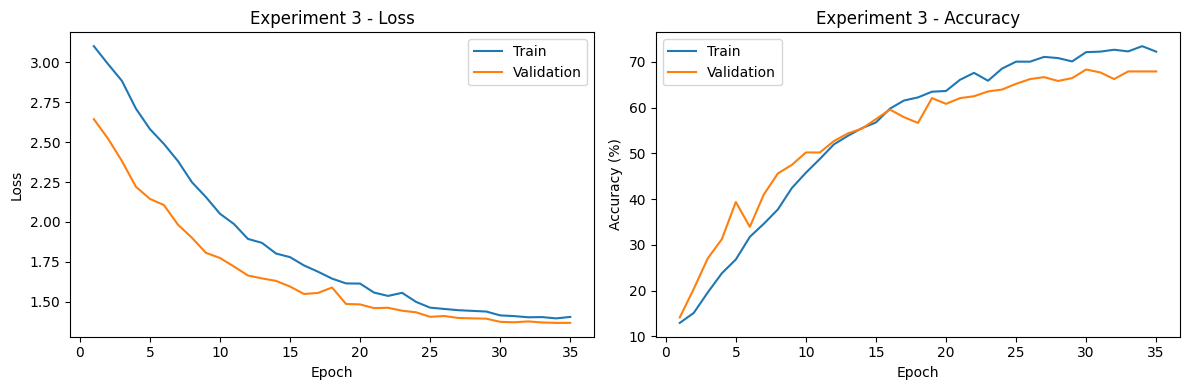


Experiment Comparison:
                        Experiment  Validation Accuracy (%)  Test Accuracy (%)
     E1 - Supervised ConvNeXt-Atto                    56.04              54.25
         E2 - SimCLR + Fine-tuning                    67.08              63.25
E3 - Joint SimCLR + Classification                    68.33              68.50


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Experiment 3 results saved successfully.


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Training curves
epochs_exp3 = range(1, len(train_losses_exp3) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_exp3, train_losses_exp3, label="Train")
axes[0].plot(epochs_exp3, val_losses_exp3, label="Validation")
axes[0].set_title("Experiment 3 - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs_exp3, train_accs_exp3, label="Train")
axes[1].plot(epochs_exp3, val_accs_exp3, label="Validation")
axes[1].set_title("Experiment 3 - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

plt.tight_layout()

curves_path_exp3 = "/content/exp3_training_curves.png"
plt.savefig(curves_path_exp3, dpi=150)
plt.show()

# Experiment comparison
# Existing Experiment 1 and 2 results are preserved here.
results_exp3 = pd.DataFrame([
    {
        "Experiment": "E1 - Supervised ConvNeXt-Atto",
        "Validation Accuracy (%)": 56.04,
        "Test Accuracy (%)": 54.25
    },
    {
        "Experiment": "E2 - SimCLR + Fine-tuning",
        "Validation Accuracy (%)": 67.08,
        "Test Accuracy (%)": 63.25
    },
    {
        "Experiment": "E3 - Joint SimCLR + Classification",
        "Validation Accuracy (%)": round(best_val_acc_exp3, 2),
        "Test Accuracy (%)": round(test_acc_exp3, 2)
    }
])

results_path_exp3 = "/content/experiment_results.csv"
results_exp3.to_csv(results_path_exp3, index=False)

print("\nExperiment Comparison:")
print(results_exp3.to_string(index=False))

# Download important files
files.download(E3_CHECKPOINT)
files.download(curves_path_exp3)
files.download(results_path_exp3)

print("\nExperiment 3 results saved successfully.")

## 8. Experiment 4: Optimized SSL-Based Scene Classification

Improving the Joint SimCLR model through high-resolution supervised fine-tuning, learning-rate scheduling, data augmentation, test-time augmentation, and validation-selected model ensembling.

### 8.1 Data Preparation and Model Initialization

Preparing scene-preserving augmentations and initializing ConvNeXt-Atto using the best Joint SimCLR checkpoint.

In [ ]:
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import ImageFolder

# Reproducibility
SEED_E4 = 42
random.seed(SEED_E4)
np.random.seed(SEED_E4)
torch.manual_seed(SEED_E4)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_E4)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Experiment 4 configuration
E4_SIZE = 288
E4_BATCH_SIZE = 16
E4_EPOCHS = 70
E4_PATIENCE = 15

E4_BACKBONE_LR = 3e-5
E4_CLASSIFIER_LR = 9e-5
E4_WEIGHT_DECAY = 0.01

E3_PATH = "/content/exp3_joint_simclr_best.pth"
E4_PATH = "/content/exp4_optimized_best.pth"

assert os.path.exists(E3_PATH), (
    "Experiment 3 checkpoint not found. "
    "Upload exp3_joint_simclr_best.pth to /content/."
)

assert "train_idx" in globals() and "val_idx" in globals(), (
    "Run your original train/validation split cell first."
)

# Preserve scene structure with moderate augmentation
train_transform_e4 = transforms.Compose([
    transforms.RandomResizedCrop(
        E4_SIZE,
        scale=(0.80, 1.0),
        ratio=(0.90, 1.10)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.12,
            hue=0.02
        )
    ], p=0.5),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(
        p=0.10,
        scale=(0.02, 0.08)
    )
])

eval_transform_e4 = transforms.Compose([
    transforms.Resize((E4_SIZE, E4_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_full_e4 = ImageFolder(
    train_dir,
    transform=train_transform_e4
)

val_full_e4 = ImageFolder(
    train_dir,
    transform=eval_transform_e4
)

train_loader_e4 = DataLoader(
    Subset(train_full_e4, train_idx),
    batch_size=E4_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader_e4 = DataLoader(
    Subset(val_full_e4, val_idx),
    batch_size=E4_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Architecture identical to Experiment 3
class JointSimCLRModel(nn.Module):
    def __init__(self, num_classes=16):
        super().__init__()

        self.backbone = timm.create_model(
            "convnext_atto",
            pretrained=False,
            num_classes=0
        )

        feature_dim = self.backbone.num_features

        self.classifier = nn.Linear(
            feature_dim,
            num_classes
        )

        self.projector = nn.Sequential(
            nn.Linear(feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 128)
        )

    def forward(self, x):
        features = self.backbone(x)
        return self.classifier(features)

# Initialize from Experiment 3
model_e4 = JointSimCLRModel(NUM_CLASSES).to(device)

model_e4.load_state_dict(
    torch.load(
        E3_PATH,
        map_location="cpu",
        weights_only=True
    ),
    strict=True
)

# Disable unused SSL projection head
for parameter in model_e4.projector.parameters():
    parameter.requires_grad = False

optimizer_e4 = torch.optim.AdamW(
    [
        {
            "params": model_e4.backbone.parameters(),
            "lr": E4_BACKBONE_LR
        },
        {
            "params": model_e4.classifier.parameters(),
            "lr": E4_CLASSIFIER_LR
        }
    ],
    weight_decay=E4_WEIGHT_DECAY
)

scheduler_e4 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_e4,
    T_max=E4_EPOCHS,
    eta_min=1e-6
)

criterion_e4 = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

scaler_e4 = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

print("Experiment 4 initialized successfully.")
print("Device:", device)
print("Training images:", len(train_loader_e4.dataset))
print("Validation images:", len(val_loader_e4.dataset))
print("Image resolution:", E4_SIZE)
print("Maximum epochs:", E4_EPOCHS)
print("Loaded checkpoint:", E3_PATH)

Experiment 4 initialized successfully.
Device: cuda
Training images: 1920
Validation images: 480
Image resolution: 288
Maximum epochs: 70
Loaded checkpoint: /content/exp3_joint_simclr_best.pth


### 8.2 High-Resolution Supervised Fine-Tuning

Fine-tuning the SSL-trained encoder using classification loss, discriminative learning rates, cosine scheduling, mixed precision, and validation-based checkpoint selection.

In [ ]:
import pandas as pd

history_e4 = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_e4 = -1.0
best_epoch_e4 = 0
no_improve_e4 = 0

start_e4 = time.time()

for epoch in range(E4_EPOCHS):

    # Training
    model_e4.train()

    running_loss = 0.0
    running_correct = 0
    running_total = 0

    for images, labels in train_loader_e4:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_e4.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = model_e4(images)
            loss = criterion_e4(logits, labels)

        scaler_e4.scale(loss).backward()
        scaler_e4.unscale_(optimizer_e4)

        torch.nn.utils.clip_grad_norm_(
            model_e4.parameters(),
            max_norm=1.0
        )

        scaler_e4.step(optimizer_e4)
        scaler_e4.update()

        running_loss += loss.item() * labels.size(0)
        running_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        running_total += labels.size(0)

    train_loss = running_loss / running_total
    train_acc = 100 * running_correct / running_total

    # Validation
    model_e4.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader_e4:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = model_e4(images)
                loss = criterion_e4(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = 100 * val_correct / val_total

    history_e4["train_loss"].append(train_loss)
    history_e4["train_acc"].append(train_acc)
    history_e4["val_loss"].append(val_loss)
    history_e4["val_acc"].append(val_acc)

    if val_acc > best_val_e4:
        best_val_e4 = val_acc
        best_epoch_e4 = epoch + 1
        no_improve_e4 = 0

        torch.save(
            model_e4.state_dict(),
            E4_PATH
        )
    else:
        no_improve_e4 += 1

    scheduler_e4.step()

    # Save history after each epoch
    pd.DataFrame(history_e4).to_csv(
        "/content/exp4_training_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch+1:02d}/{E4_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Best: {best_val_e4:.2f}%"
    )

    if no_improve_e4 >= E4_PATIENCE:
        print("Early stopping triggered.")
        break

training_time_e4 = (time.time() - start_e4) / 60

print("\nExperiment 4 training completed.")
print("Best epoch:", best_epoch_e4)
print(f"Best validation accuracy: {best_val_e4:.2f}%")
print(f"Training time: {training_time_e4:.2f} minutes")
print("Best checkpoint:", E4_PATH)

Epoch 01/70 | Train Loss: 1.0865 | Train Acc: 72.14% | Val Loss: 1.1453 | Val Acc: 70.21% | Best: 70.21%
Epoch 02/70 | Train Loss: 1.0584 | Train Acc: 72.81% | Val Loss: 1.1263 | Val Acc: 69.58% | Best: 70.21%
Epoch 03/70 | Train Loss: 1.0381 | Train Acc: 74.01% | Val Loss: 1.1019 | Val Acc: 72.08% | Best: 72.08%
Epoch 04/70 | Train Loss: 1.0204 | Train Acc: 75.00% | Val Loss: 1.1154 | Val Acc: 69.38% | Best: 72.08%
Epoch 05/70 | Train Loss: 1.0025 | Train Acc: 75.21% | Val Loss: 1.1029 | Val Acc: 70.42% | Best: 72.08%
Epoch 06/70 | Train Loss: 0.9887 | Train Acc: 75.94% | Val Loss: 1.0931 | Val Acc: 71.88% | Best: 72.08%
Epoch 07/70 | Train Loss: 0.9748 | Train Acc: 76.67% | Val Loss: 1.1142 | Val Acc: 69.17% | Best: 72.08%
Epoch 08/70 | Train Loss: 0.9682 | Train Acc: 76.46% | Val Loss: 1.0826 | Val Acc: 73.12% | Best: 73.12%
Epoch 09/70 | Train Loss: 0.9654 | Train Acc: 77.45% | Val Loss: 1.0772 | Val Acc: 68.96% | Best: 73.12%
Epoch 10/70 | Train Loss: 0.9556 | Train Acc: 77.50% | 

### 8.3 Test-Time Augmentation and Ensemble Evaluation

Evaluating the optimized model using horizontal-flip augmentation and combining predictions from Experiments 3 and 4. Selecting the strongest configuration using validation accuracy.

Validation configuration comparison:
Ensemble E4 weight 0.8: 75.00%
Ensemble E4 weight 0.6: 74.79%
E4 without TTA: 74.58%
Ensemble E4 weight 0.4: 74.58%
Ensemble E4 weight 0.9: 74.58%
Ensemble E4 weight 0.3: 74.37%
Ensemble E4 weight 0.5: 74.37%
Ensemble E4 weight 0.7: 74.37%
E4 with TTA: 74.17%
Ensemble E4 weight 0.2: 72.29%
Ensemble E4 weight 0.1: 71.88%
E3 with TTA: 69.79%

Selected: Ensemble E4 weight 0.8
Selected validation accuracy: 75.00%

Experiment 4 Final Results
Selected configuration: Ensemble E4 weight 0.8
Validation Accuracy: 75.00%
Test Accuracy: 71.75%
Training Time: 12.25 minutes


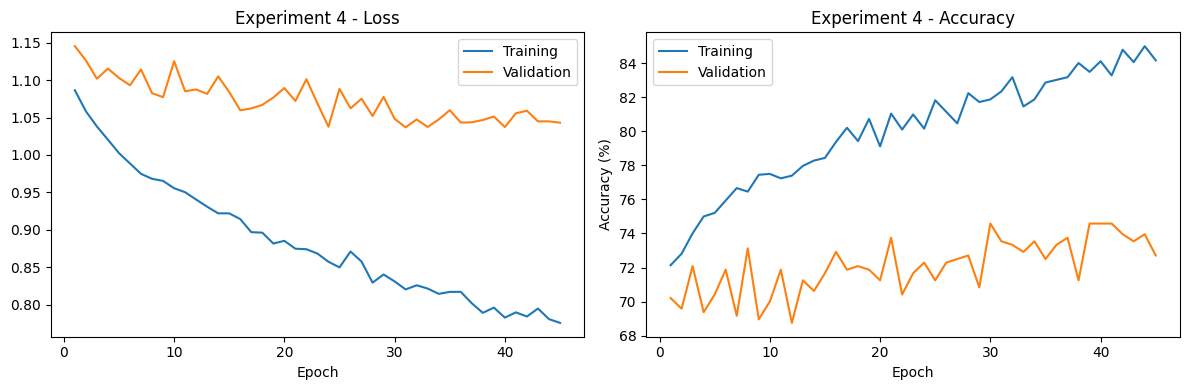


Experiment comparison:
                             Experiment  Validation Accuracy (%)  Test Accuracy (%)
          E1 - Supervised ConvNeXt-Atto                    56.04              54.25
              E2 - SimCLR + Fine-tuning                    67.08              63.25
     E3 - Joint SimCLR + Classification                    68.33              68.50
E4 - Optimized SSL-Based Classification                    75.00              71.75


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch.nn.functional as F
from google.colab import files

# Reload best E4 checkpoint
model_e4.load_state_dict(
    torch.load(
        E4_PATH,
        map_location=device,
        weights_only=True
    )
)
model_e4.eval()

# Load E3 independently
model_e3 = JointSimCLRModel(NUM_CLASSES).to(device)
model_e3.load_state_dict(
    torch.load(
        E3_PATH,
        map_location=device,
        weights_only=True
    )
)
model_e3.eval()

# Test dataset: same class order and evaluation transform
test_dataset_e4 = ImageFolder(
    test_dir,
    transform=eval_transform_e4
)

assert train_full_e4.classes == test_dataset_e4.classes, (
    "Training and test class ordering does not match."
)

test_loader_e4 = DataLoader(
    test_dataset_e4,
    batch_size=E4_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

@torch.no_grad()
def predict_probabilities(model, loader, tta=False):
    model.eval()

    probabilities = []
    labels_all = []

    for images, labels in loader:
        images = images.to(device)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = model(images)

        probs = F.softmax(logits.float(), dim=1)

        if tta:
            flipped_images = torch.flip(images, dims=[3])

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                flipped_logits = model(flipped_images)

            flipped_probs = F.softmax(
                flipped_logits.float(),
                dim=1
            )

            probs = (probs + flipped_probs) / 2

        probabilities.append(probs.cpu())
        labels_all.append(labels.cpu())

    return (
        torch.cat(probabilities),
        torch.cat(labels_all)
    )

def accuracy_from_probs(probs, labels):
    return 100 * (
        probs.argmax(dim=1) == labels
    ).float().mean().item()

# Validation predictions
e3_val_probs, val_labels = predict_probabilities(
    model_e3, val_loader_e4, tta=True
)

e4_val_probs, val_labels_check = predict_probabilities(
    model_e4, val_loader_e4, tta=True
)

e4_plain_val_probs, _ = predict_probabilities(
    model_e4, val_loader_e4, tta=False
)

assert torch.equal(val_labels, val_labels_check)

# Candidate selection using validation only
candidates = {
    "E3 with TTA": e3_val_probs,
    "E4 without TTA": e4_plain_val_probs,
    "E4 with TTA": e4_val_probs
}

for e4_weight in np.linspace(0.1, 0.9, 9):
    e3_weight = 1.0 - e4_weight

    combined = (
        e3_weight * e3_val_probs
        + e4_weight * e4_val_probs
    )

    candidates[
        f"Ensemble E4 weight {e4_weight:.1f}"
    ] = combined

candidate_scores = {
    name: accuracy_from_probs(probs, val_labels)
    for name, probs in candidates.items()
}

best_config_e4 = max(
    candidate_scores,
    key=candidate_scores.get
)

best_final_val_e4 = candidate_scores[best_config_e4]

print("Validation configuration comparison:")
for name, score in sorted(
    candidate_scores.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{name}: {score:.2f}%")

print("\nSelected:", best_config_e4)
print(f"Selected validation accuracy: {best_final_val_e4:.2f}%")

# Test predictions (after validation selection)
e3_test_probs, test_labels = predict_probabilities(
    model_e3, test_loader_e4, tta=True
)

e4_test_probs, test_labels_check = predict_probabilities(
    model_e4, test_loader_e4, tta=True
)

assert torch.equal(test_labels, test_labels_check)

if best_config_e4 == "E3 with TTA":
    final_test_probs = e3_test_probs

elif best_config_e4 == "E4 without TTA":
    final_test_probs, _ = predict_probabilities(
        model_e4, test_loader_e4, tta=False
    )

elif best_config_e4 == "E4 with TTA":
    final_test_probs = e4_test_probs

else:
    weight = float(best_config_e4.split()[-1])

    final_test_probs = (
        (1.0 - weight) * e3_test_probs
        + weight * e4_test_probs
    )

final_test_acc_e4 = accuracy_from_probs(
    final_test_probs,
    test_labels
)

print("\nExperiment 4 Final Results")
print("Selected configuration:", best_config_e4)
print(f"Validation Accuracy: {best_final_val_e4:.2f}%")
print(f"Test Accuracy: {final_test_acc_e4:.2f}%")
print(f"Training Time: {training_time_e4:.2f} minutes")

# Training curves
epochs_plot = range(
    1, len(history_e4["train_acc"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs_plot,
    history_e4["train_loss"],
    label="Training"
)
axes[0].plot(
    epochs_plot,
    history_e4["val_loss"],
    label="Validation"
)
axes[0].set_title("Experiment 4 - Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(
    epochs_plot,
    history_e4["train_acc"],
    label="Training"
)
axes[1].plot(
    epochs_plot,
    history_e4["val_acc"],
    label="Validation"
)
axes[1].set_title("Experiment 4 - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

plt.tight_layout()

curves_path_e4 = "/content/exp4_training_curves.png"
plt.savefig(curves_path_e4, dpi=150)
plt.show()

# Comparison table
comparison_e4 = pd.DataFrame([
    ["E1 - Supervised ConvNeXt-Atto", 56.04, 54.25],
    ["E2 - SimCLR + Fine-tuning", 67.08, 63.25],
    ["E3 - Joint SimCLR + Classification", 68.33, 68.50],
    ["E4 - Optimized SSL-Based Classification",
     round(best_final_val_e4, 2),
     round(final_test_acc_e4, 2)]
], columns=[
    "Experiment",
    "Validation Accuracy (%)",
    "Test Accuracy (%)"
])

comparison_path_e4 = "/content/experiment_results.csv"
comparison_e4.to_csv(comparison_path_e4, index=False)

print("\nExperiment comparison:")
print(comparison_e4.to_string(index=False))

# Save selected inference configuration
import json

config_path_e4 = "/content/exp4_inference_config.json"

with open(config_path_e4, "w") as f:
    json.dump({
        "selected_configuration": best_config_e4,
        "validation_accuracy": best_final_val_e4,
        "test_accuracy": final_test_acc_e4,
        "image_size": E4_SIZE,
        "classes": train_full_e4.classes
    }, f, indent=2)

# Download results
for path in [
    E4_PATH,
    curves_path_e4,
    comparison_path_e4,
    config_path_e4,
    "/content/exp4_training_history.csv"
]:
    files.download(path)

## 9. Experiment 5: ResNet-18 + MoCo v2 Self-Supervised Pretraining + Advanced Fine-Tuning

This experiment uses Momentum Contrast v2 (MoCo v2) to learn visual representations without labels, followed by supervised fine-tuning of ResNet-18. MixUp, CutMix, learning-rate scheduling, and regularization are used during fine-tuning. Test-time augmentation is also evaluated, with the final inference strategy selected using validation accuracy.

### 9.1 Data Preparation and MoCo v2 Model Initialization

Preparing the training and validation datasets, constructing the query and momentum encoders, and initializing the contrastive memory queue for self-supervised learning.

In [12]:
import os, time, random, copy, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image, ImageFilter
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from timm.data import Mixup
from timm.loss import SoftTargetCrossEntropy

# ============================================================
# CONFIGURATION
# ============================================================

E5_SEED = 42
random.seed(E5_SEED)
np.random.seed(E5_SEED)
torch.manual_seed(E5_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(E5_SEED)

e5_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.backends.cudnn.benchmark = True

E5_SIZE = 224
E5_SSL_BATCH = 64
E5_FT_BATCH = 32

E5_SSL_EPOCHS = 100
E5_FT_EPOCHS = 70
E5_FT_PATIENCE = 15

E5_QUEUE_SIZE = 4096
E5_FEATURE_DIM = 128
E5_MOMENTUM = 0.999
E5_TEMPERATURE = 0.2

E5_DIR = "/content/experiment5"
os.makedirs(E5_DIR, exist_ok=True)

E5_SSL_BEST = f"{E5_DIR}/moco_v2_best.pth"
E5_SSL_LAST = f"{E5_DIR}/moco_v2_latest.pth"
E5_FT_BEST = f"{E5_DIR}/resnet18_moco_finetuned_best.pth"
E5_FT_LAST = f"{E5_DIR}/finetune_latest.pth"

E5_MEAN = [0.485, 0.456, 0.406]
E5_STD = [0.229, 0.224, 0.225]

for name in ["train_dir", "test_dir", "train_idx", "val_idx"]:
    assert name in globals(), (
        f"Missing {name}. Run the common dataset setup first."
    )

# ============================================================
# AUGMENTATION
# ============================================================

class E5GaussianBlur:
    def __init__(self, radius=(0.1, 2.0)):
        self.radius = radius

    def __call__(self, image):
        sigma = random.uniform(*self.radius)
        return image.filter(
            ImageFilter.GaussianBlur(radius=sigma)
        )

# Two independently augmented views for MoCo
e5_ssl_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        E5_SIZE,
        scale=(0.4, 1.0)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.4,
            contrast=0.4,
            saturation=0.4,
            hue=0.1
        )
    ], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    transforms.RandomApply([
        E5GaussianBlur()
    ], p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(E5_MEAN, E5_STD)
])

# Supervised fine-tuning augmentation
e5_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        E5_SIZE,
        scale=(0.75, 1.0),
        ratio=(0.85, 1.15)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.12,
            hue=0.02
        )
    ], p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(E5_MEAN, E5_STD),
    transforms.RandomErasing(
        p=0.10,
        scale=(0.02, 0.08)
    )
])

e5_eval_transform = transforms.Compose([
    transforms.Resize((E5_SIZE, E5_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(E5_MEAN, E5_STD)
])

# ============================================================
# DATASETS
# ============================================================

e5_train_base = ImageFolder(train_dir)
e5_classes = e5_train_base.classes
E5_NUM_CLASSES = len(e5_classes)

assert E5_NUM_CLASSES == 16

e5_train_idx = list(map(int, train_idx))
e5_val_idx = list(map(int, val_idx))

assert not set(e5_train_idx).intersection(e5_val_idx)
assert len(e5_train_idx) == 1920
assert len(e5_val_idx) == 480

class E5TwoViews(Dataset):
    def __init__(self, base, indices, transform):
        self.base = base
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        actual_index = self.indices[index]
        path, _ = self.base.samples[actual_index]

        with Image.open(path) as image:
            image = image.convert("RGB")
            q = self.transform(image)
            k = self.transform(image)

        return q, k

e5_ssl_dataset = E5TwoViews(
    e5_train_base,
    e5_train_idx,
    e5_ssl_transform
)

e5_supervised_train = ImageFolder(
    train_dir,
    transform=e5_train_transform
)

e5_supervised_val = ImageFolder(
    train_dir,
    transform=e5_eval_transform
)

e5_ssl_loader = DataLoader(
    e5_ssl_dataset,
    batch_size=E5_SSL_BATCH,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=(e5_device.type == "cuda")
)

e5_train_loader = DataLoader(
    Subset(e5_supervised_train, e5_train_idx),
    batch_size=E5_FT_BATCH,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=(e5_device.type == "cuda")
)

e5_val_loader = DataLoader(
    Subset(e5_supervised_val, e5_val_idx),
    batch_size=E5_FT_BATCH,
    shuffle=False,
    num_workers=2,
    pin_memory=(e5_device.type == "cuda")
)

# ============================================================
# RESNET-18 ENCODER
# ============================================================

def e5_make_encoder():
    encoder = models.resnet18(weights=None)

    feature_dim = encoder.fc.in_features

    # MoCo v2 two-layer projection head
    encoder.fc = nn.Sequential(
        nn.Linear(feature_dim, 512),
        nn.ReLU(inplace=True),
        nn.Linear(512, E5_FEATURE_DIM)
    )

    return encoder

# ============================================================
# MoCo v2 MODEL
# ============================================================

class E5MoCo(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder_q = e5_make_encoder()
        self.encoder_k = e5_make_encoder()

        # Initialize key encoder from query encoder
        for q, k in zip(
            self.encoder_q.parameters(),
            self.encoder_k.parameters()
        ):
            k.data.copy_(q.data)
            k.requires_grad = False

        queue = F.normalize(
            torch.randn(
                E5_FEATURE_DIM,
                E5_QUEUE_SIZE
            ),
            dim=0
        )

        self.register_buffer("queue", queue)
        self.register_buffer(
            "queue_ptr",
            torch.zeros(1, dtype=torch.long)
        )

    @torch.no_grad()
    def momentum_update(self):

        for q, k in zip(
            self.encoder_q.parameters(),
            self.encoder_k.parameters()
        ):
            k.data.mul_(E5_MOMENTUM).add_(
                q.data,
                alpha=1.0 - E5_MOMENTUM
            )

        # Copy running BatchNorm statistics
        for q_buffer, k_buffer in zip(
            self.encoder_q.buffers(),
            self.encoder_k.buffers()
        ):
            k_buffer.copy_(q_buffer)

    @torch.no_grad()
    def enqueue(self, keys):

        keys = keys.detach()
        batch_size = keys.shape[0]

        ptr = int(self.queue_ptr.item())
        end = ptr + batch_size

        if end <= E5_QUEUE_SIZE:
            self.queue[:, ptr:end] = keys.T
        else:
            first = E5_QUEUE_SIZE - ptr
            self.queue[:, ptr:] = keys[:first].T
            self.queue[:, :end - E5_QUEUE_SIZE] = keys[first:].T

        self.queue_ptr[0] = end % E5_QUEUE_SIZE

    def forward(self, im_q, im_k):

        q = F.normalize(
            self.encoder_q(im_q),
            dim=1
        )

        with torch.no_grad():
            self.momentum_update()

            # Shuffle keys before BatchNorm, then undo shuffle
            permutation = torch.randperm(
                im_k.size(0),
                device=im_k.device
            )
            inverse = torch.argsort(permutation)

            k = self.encoder_k(im_k[permutation])
            k = F.normalize(k, dim=1)
            k = k[inverse]

        positive = torch.sum(
            q * k,
            dim=1,
            keepdim=True
        )

        negative = torch.mm(
            q,
            self.queue.clone().detach()
        )

        logits = torch.cat(
            [positive, negative],
            dim=1
        ) / E5_TEMPERATURE

        labels = torch.zeros(
            logits.size(0),
            dtype=torch.long,
            device=logits.device
        )

        loss = F.cross_entropy(logits, labels)

        self.enqueue(k)

        return loss

e5_moco = E5MoCo().to(e5_device)

print("Experiment 5 initialized successfully.")
print("Device:", e5_device)
print("Architecture: ResNet-18")
print("SSL: MoCo v2")
print("Training images:", len(e5_ssl_dataset))
print("Validation images:", len(e5_val_idx))
print("Classes:", E5_NUM_CLASSES)
print("MoCo queue:", E5_QUEUE_SIZE)
print("SSL epochs:", E5_SSL_EPOCHS)
print("Fine-tuning epochs:", E5_FT_EPOCHS)

Experiment 5 initialized successfully.
Device: cuda
Architecture: ResNet-18
SSL: MoCo v2
Training images: 1920
Validation images: 480
Classes: 16
MoCo queue: 4096
SSL epochs: 100
Fine-tuning epochs: 70


### 9.2 MoCo v2 Self-Supervised Pretraining

Training the query encoder using contrastive learning while updating the key encoder through momentum. Maintain a memory queue of negative representations and save the pretrained encoder for supervised fine-tuning.

In [13]:
# ============================================================
# EXPERIMENT 5 - MoCo v2 SELF-SUPERVISED PRETRAINING
# ============================================================

e5_ssl_optimizer = torch.optim.SGD(
    e5_moco.encoder_q.parameters(),
    lr=0.03,
    momentum=0.9,
    weight_decay=1e-4
)

e5_ssl_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    e5_ssl_optimizer,
    T_max=E5_SSL_EPOCHS,
    eta_min=1e-5
)

e5_ssl_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(e5_device.type == "cuda")
)

e5_ssl_history = []
e5_ssl_start_epoch = 0
e5_ssl_best_loss = float("inf")

# Resume if an earlier SSL run was interrupted
if os.path.exists(E5_SSL_LAST):

    state = torch.load(
        E5_SSL_LAST,
        map_location="cpu",
        weights_only=False
    )

    e5_moco.load_state_dict(state["model"])
    e5_ssl_optimizer.load_state_dict(state["optimizer"])
    e5_ssl_scheduler.load_state_dict(state["scheduler"])

    if state.get("scaler") is not None:
        e5_ssl_scaler.load_state_dict(state["scaler"])

    e5_ssl_start_epoch = state["epoch"]
    e5_ssl_best_loss = state["best_loss"]
    e5_ssl_history = state["history"]

    print(
        "Resuming MoCo pretraining from epoch",
        e5_ssl_start_epoch
    )

e5_ssl_start_time = time.time()

for epoch in range(
    e5_ssl_start_epoch,
    E5_SSL_EPOCHS
):

    e5_moco.train()

    # Key encoder is used only for forward inference
    e5_moco.encoder_k.eval()

    total_loss = 0.0
    total_images = 0

    for images_q, images_k in e5_ssl_loader:

        images_q = images_q.to(
            e5_device,
            non_blocking=True
        )
        images_k = images_k.to(
            e5_device,
            non_blocking=True
        )

        e5_ssl_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=e5_device.type,
            enabled=(e5_device.type == "cuda")
        ):
            loss = e5_moco(images_q, images_k)

        e5_ssl_scaler.scale(loss).backward()
        e5_ssl_scaler.unscale_(e5_ssl_optimizer)

        torch.nn.utils.clip_grad_norm_(
            e5_moco.encoder_q.parameters(),
            max_norm=5.0
        )

        e5_ssl_scaler.step(e5_ssl_optimizer)
        e5_ssl_scaler.update()

        total_loss += loss.item() * images_q.size(0)
        total_images += images_q.size(0)

    avg_loss = total_loss / total_images

    e5_ssl_scheduler.step()

    e5_ssl_history.append({
        "epoch": epoch + 1,
        "ssl_loss": avg_loss
    })

    # Save latest state for resuming
    torch.save({
        "epoch": epoch + 1,
        "model": e5_moco.state_dict(),
        "optimizer": e5_ssl_optimizer.state_dict(),
        "scheduler": e5_ssl_scheduler.state_dict(),
        "scaler": e5_ssl_scaler.state_dict(),
        "best_loss": min(e5_ssl_best_loss, avg_loss),
        "history": e5_ssl_history
    }, E5_SSL_LAST)

    if avg_loss < e5_ssl_best_loss:

        e5_ssl_best_loss = avg_loss

        torch.save(
            e5_moco.encoder_q.state_dict(),
            E5_SSL_BEST
        )

    pd.DataFrame(e5_ssl_history).to_csv(
        f"{E5_DIR}/moco_v2_history.csv",
        index=False
    )

    print(
        f"SSL Epoch {epoch+1:03d}/{E5_SSL_EPOCHS} | "
        f"Loss: {avg_loss:.4f} | "
        f"Best Loss: {e5_ssl_best_loss:.4f}"
    )

e5_ssl_minutes = (
    time.time() - e5_ssl_start_time
) / 60

print("\nMoCo v2 pretraining completed.")
print("Best SSL training loss:", round(e5_ssl_best_loss, 4))
print("Time:", round(e5_ssl_minutes, 2), "minutes")
print("Saved encoder:", E5_SSL_BEST)

SSL Epoch 001/100 | Loss: 6.1536 | Best Loss: 6.1536
SSL Epoch 002/100 | Loss: 7.2582 | Best Loss: 6.1536
SSL Epoch 003/100 | Loss: 7.5888 | Best Loss: 6.1536
SSL Epoch 004/100 | Loss: 7.6174 | Best Loss: 6.1536
SSL Epoch 005/100 | Loss: 7.6049 | Best Loss: 6.1536
SSL Epoch 006/100 | Loss: 7.6220 | Best Loss: 6.1536
SSL Epoch 007/100 | Loss: 7.6090 | Best Loss: 6.1536
SSL Epoch 008/100 | Loss: 7.6400 | Best Loss: 6.1536
SSL Epoch 009/100 | Loss: 7.6071 | Best Loss: 6.1536
SSL Epoch 010/100 | Loss: 7.6679 | Best Loss: 6.1536
SSL Epoch 011/100 | Loss: 7.6576 | Best Loss: 6.1536
SSL Epoch 012/100 | Loss: 7.6912 | Best Loss: 6.1536
SSL Epoch 013/100 | Loss: 7.6737 | Best Loss: 6.1536
SSL Epoch 014/100 | Loss: 7.7728 | Best Loss: 6.1536
SSL Epoch 015/100 | Loss: 7.7756 | Best Loss: 6.1536
SSL Epoch 016/100 | Loss: 7.7426 | Best Loss: 6.1536
SSL Epoch 017/100 | Loss: 7.5664 | Best Loss: 6.1536
SSL Epoch 018/100 | Loss: 7.4825 | Best Loss: 6.1536
SSL Epoch 019/100 | Loss: 7.5446 | Best Loss: 

In [14]:
from google.colab import files

files.download(
    "/content/experiment5/moco_v2_best.pth"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 9.3 Advanced Supervised Fine-Tuning

Transfer the MoCo v2 encoder to a 16-class ResNet-18 classifier and fine-tune it using MixUp, CutMix, discriminative learning rates, AdamW, cosine scheduling, mixed precision, gradient clipping, and validation-based early stopping.

In [18]:
# ============================================================
# EXPERIMENT 5 - ADVANCED SUPERVISED FINE-TUNING
# ============================================================

assert os.path.exists(E5_SSL_BEST), (
    "MoCo encoder checkpoint missing. "
    "Complete Section 9.2 first."
)

# ------------------------------------------------------------
# 1. BUILD CLASSIFIER
# ------------------------------------------------------------

e5_classifier = models.resnet18(
    weights=None
)

e5_classifier.fc = nn.Linear(
    e5_classifier.fc.in_features,
    E5_NUM_CLASSES
)

# Load backbone weights from MoCo query encoder
e5_ssl_weights = torch.load(
    E5_SSL_BEST,
    map_location="cpu",
    weights_only=True
)

backbone_weights = {
    key: value
    for key, value in e5_ssl_weights.items()
    if not key.startswith("fc.")
}

load_result = e5_classifier.load_state_dict(
    backbone_weights,
    strict=False
)

assert set(load_result.missing_keys) == {
    "fc.weight", "fc.bias"
}, load_result.missing_keys

assert not load_result.unexpected_keys

e5_classifier = e5_classifier.to(e5_device)

# ------------------------------------------------------------
# 2. MIXUP AND CUTMIX
# ------------------------------------------------------------

e5_mixup = Mixup(
    mixup_alpha=0.2,
    cutmix_alpha=0.5,
    prob=0.65,
    switch_prob=0.5,
    mode="batch",
    label_smoothing=0.05,
    num_classes=E5_NUM_CLASSES
)

e5_train_criterion = SoftTargetCrossEntropy()
e5_val_criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# 3. DISCRIMINATIVE LEARNING RATES
# ------------------------------------------------------------

e5_ft_optimizer = torch.optim.AdamW([
    {
        "params": [
            p for name, p in e5_classifier.named_parameters()
            if not name.startswith("fc.")
        ],
        "lr": 3e-4
    },
    {
        "params": e5_classifier.fc.parameters(),
        "lr": 1e-3
    }
], weight_decay=0.02)

e5_ft_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    e5_ft_optimizer,
    T_max=E5_FT_EPOCHS,
    eta_min=1e-6
)

e5_ft_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(e5_device.type == "cuda")
)

# ------------------------------------------------------------
# 4. RESUME SUPPORT
# ------------------------------------------------------------

e5_ft_history = []
e5_ft_start_epoch = 0
e5_ft_best_val = -1.0
e5_ft_best_epoch = 0
e5_ft_no_improve = 0

if os.path.exists(E5_FT_LAST):

    state = torch.load(
        E5_FT_LAST,
        map_location="cpu",
        weights_only=False
    )

    e5_classifier.load_state_dict(state["model"])
    e5_ft_optimizer.load_state_dict(state["optimizer"])
    e5_ft_scheduler.load_state_dict(state["scheduler"])

    if state.get("scaler") is not None:
        e5_ft_scaler.load_state_dict(state["scaler"])

    e5_ft_start_epoch = state["epoch"]
    e5_ft_best_val = state["best_val"]
    e5_ft_best_epoch = state["best_epoch"]
    e5_ft_no_improve = state["no_improve"]
    e5_ft_history = state["history"]

    print(
        "Resuming fine-tuning from epoch",
        e5_ft_start_epoch
    )

# ------------------------------------------------------------
# 5. TRAINING
# ------------------------------------------------------------

e5_ft_start_time = time.time()

for epoch in range(
    e5_ft_start_epoch,
    E5_FT_EPOCHS
):

    e5_classifier.train()

    running_train_loss = 0.0
    train_total = 0

    for images, labels in e5_train_loader:

        images = images.to(
            e5_device,
            non_blocking=True
        )
        labels = labels.to(
            e5_device,
            non_blocking=True
        )

        images, soft_labels = e5_mixup(
            images, labels
        )

        e5_ft_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=e5_device.type,
            enabled=(e5_device.type == "cuda")
        ):
            logits = e5_classifier(images)

            loss = e5_train_criterion(
                logits,
                soft_labels
            )

        e5_ft_scaler.scale(loss).backward()
        e5_ft_scaler.unscale_(e5_ft_optimizer)

        torch.nn.utils.clip_grad_norm_(
            e5_classifier.parameters(),
            max_norm=1.0
        )

        e5_ft_scaler.step(e5_ft_optimizer)
        e5_ft_scaler.update()

        running_train_loss += (
            loss.item() * images.size(0)
        )

        train_total += images.size(0)

    train_loss = running_train_loss / train_total

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    e5_classifier.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in e5_val_loader:

            images = images.to(e5_device)
            labels = labels.to(e5_device)

            with torch.autocast(
                device_type=e5_device.type,
                enabled=(e5_device.type == "cuda")
            ):
                logits = e5_classifier(images)
                loss = e5_val_criterion(
                    logits, labels
                )

            val_loss_sum += (
                loss.item() * labels.size(0)
            )

            val_correct += (
                logits.argmax(1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = 100 * val_correct / val_total

    e5_ft_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    # --------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------

    if val_acc > e5_ft_best_val:

        e5_ft_best_val = val_acc
        e5_ft_best_epoch = epoch + 1
        e5_ft_no_improve = 0

        torch.save(
            e5_classifier.state_dict(),
            E5_FT_BEST
        )

    else:
        e5_ft_no_improve += 1

    e5_ft_scheduler.step()

    # Save resumable checkpoint
    torch.save({
        "epoch": epoch + 1,
        "model": e5_classifier.state_dict(),
        "optimizer": e5_ft_optimizer.state_dict(),
        "scheduler": e5_ft_scheduler.state_dict(),
        "scaler": e5_ft_scaler.state_dict(),
        "best_val": e5_ft_best_val,
        "best_epoch": e5_ft_best_epoch,
        "no_improve": e5_ft_no_improve,
        "history": e5_ft_history
    }, E5_FT_LAST)

    pd.DataFrame(e5_ft_history).to_csv(
        f"{E5_DIR}/finetune_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch+1:02d}/{E5_FT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Best: {e5_ft_best_val:.2f}%"
    )

    if e5_ft_no_improve >= E5_FT_PATIENCE:
        print("Early stopping triggered.")
        break

e5_ft_minutes = (
    time.time() - e5_ft_start_time
) / 60

print("\nFine-tuning completed.")
print("Best epoch:", e5_ft_best_epoch)
print(f"Best validation accuracy: {e5_ft_best_val:.2f}%")
print(f"Fine-tuning time: {e5_ft_minutes:.2f} minutes")
print("Best checkpoint:", E5_FT_BEST)

Epoch 01/50 | Train Loss: 2.3841 | Val Loss: 2.3325 | Val Acc: 30.83% | Best: 30.83%
Epoch 02/50 | Train Loss: 1.9292 | Val Loss: 1.4910 | Val Acc: 48.75% | Best: 48.75%
Epoch 03/50 | Train Loss: 1.7924 | Val Loss: 1.9023 | Val Acc: 47.08% | Best: 48.75%
Epoch 04/50 | Train Loss: 1.7083 | Val Loss: 1.2708 | Val Acc: 56.46% | Best: 56.46%
Epoch 05/50 | Train Loss: 1.5277 | Val Loss: 1.2664 | Val Acc: 59.38% | Best: 59.38%
Epoch 06/50 | Train Loss: 1.4802 | Val Loss: 1.3512 | Val Acc: 56.67% | Best: 59.38%
Epoch 07/50 | Train Loss: 1.4091 | Val Loss: 1.3208 | Val Acc: 61.04% | Best: 61.04%
Epoch 08/50 | Train Loss: 1.4261 | Val Loss: 1.0914 | Val Acc: 64.38% | Best: 64.38%
Epoch 09/50 | Train Loss: 1.2093 | Val Loss: 1.1282 | Val Acc: 67.08% | Best: 67.08%
Epoch 10/50 | Train Loss: 1.3387 | Val Loss: 0.9557 | Val Acc: 68.33% | Best: 68.33%
Epoch 11/50 | Train Loss: 1.2041 | Val Loss: 1.1175 | Val Acc: 62.71% | Best: 68.33%
Epoch 12/50 | Train Loss: 1.2213 | Val Loss: 1.1870 | Val Acc: 62

In [19]:
from google.colab import files

files.download(
    "/content/experiment5/resnet18_moco_finetuned_best.pth"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 9.4 Test-Time Augmentation, Evaluation and Visualization

The best ResNet-18 classifier is evaluated with and without horizontal-flip test-time augmentation. The inference strategy is selected based on validation accuracy before evaluating the held-out test dataset. The final model achieves 81.67% validation accuracy and 76.00% test accuracy. The training curves, experiment results, and inference configuration are saved for reproducibility.

Validation without TTA: 81.67%
Validation with TTA: 81.25%
Selected TTA: False

EXPERIMENT 5 FINAL RESULTS
Validation Accuracy: 81.67%
Test Accuracy: 76.00%


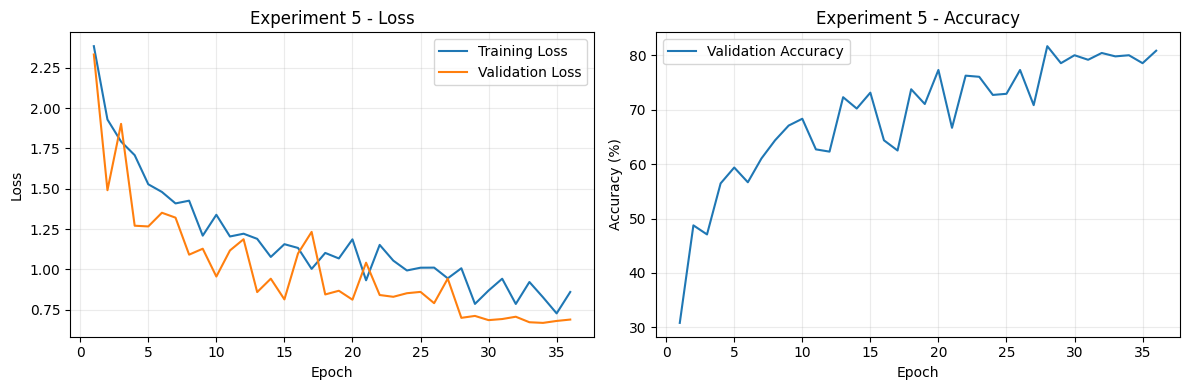

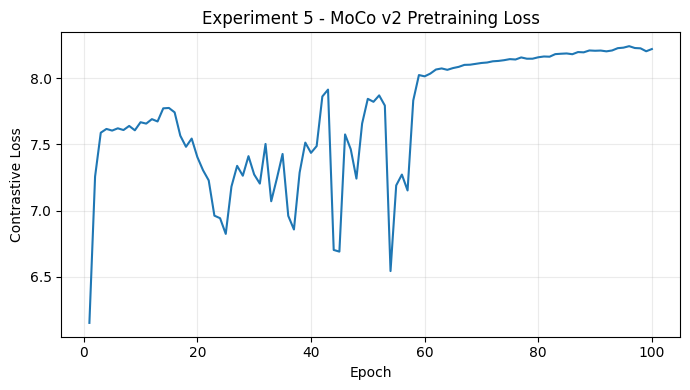


Experiment Comparison:
                                           Experiment  Validation Accuracy (%)  Test Accuracy (%)
                        E1 - Supervised ConvNeXt-Atto                    56.04              54.25
                            E2 - SimCLR + Fine-tuning                    67.08              63.25
                   E3 - Joint SimCLR + Classification                    68.33              68.50
              E4 - Optimized SSL-Based Classification                    75.00              71.75
E5 - ResNet-18 + MoCo v2 + Advanced Fine-Tuning + TTA                    81.67              76.00

Experiment 5 files packaged:
/content/experiment5_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# ============================================================
# EXPERIMENT 5 - FINAL EVALUATION AND DOWNLOADS
# ============================================================

import os, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from google.colab import files

E5_DIR = "/content/experiment5"
E5_FT_BEST = f"{E5_DIR}/resnet18_moco_finetuned_best.pth"
E5_HISTORY_PATH = f"{E5_DIR}/finetune_history.csv"
E5_SSL_HISTORY_PATH = f"{E5_DIR}/moco_v2_history.csv"

E5_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert os.path.exists(E5_FT_BEST), (
    "Fine-tuned checkpoint missing. "
    "Restore it from your saved files."
)

assert os.path.exists(E5_HISTORY_PATH), (
    "Fine-tuning history missing."
)

assert "train_dir" in globals()
assert "test_dir" in globals()
assert "val_idx" in globals()

# ------------------------------------------------------------
# 1. RESTORE DATA AND MODEL
# ------------------------------------------------------------

e5_eval_transform_final = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

e5_val_full_final = ImageFolder(
    train_dir,
    transform=e5_eval_transform_final
)

e5_test_full_final = ImageFolder(
    test_dir,
    transform=e5_eval_transform_final
)

assert (
    e5_val_full_final.classes
    == e5_test_full_final.classes
)

e5_num_classes_final = len(
    e5_val_full_final.classes
)

e5_val_loader_final = DataLoader(
    Subset(e5_val_full_final, val_idx),
    batch_size=32,
    shuffle=False,
    num_workers=2
)

e5_test_loader_final = DataLoader(
    e5_test_full_final,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

e5_final_model = models.resnet18(weights=None)

e5_final_model.fc = nn.Linear(
    e5_final_model.fc.in_features,
    e5_num_classes_final
)

e5_final_model.load_state_dict(
    torch.load(
        E5_FT_BEST,
        map_location="cpu",
        weights_only=True
    )
)

e5_final_model = e5_final_model.to(E5_DEVICE)
e5_final_model.eval()

# ------------------------------------------------------------
# 2. INFERENCE WITH OPTIONAL TTA
# ------------------------------------------------------------

@torch.no_grad()
def e5_predict_final(model, loader, tta=False):

    model.eval()

    all_probs = []
    all_labels = []

    for images, labels in loader:

        images = images.to(E5_DEVICE)

        with torch.autocast(
            device_type=E5_DEVICE.type,
            enabled=(E5_DEVICE.type == "cuda")
        ):
            logits = model(images)

        probs = F.softmax(
            logits.float(),
            dim=1
        )

        if tta:

            flipped = torch.flip(
                images,
                dims=[3]
            )

            with torch.autocast(
                device_type=E5_DEVICE.type,
                enabled=(E5_DEVICE.type == "cuda")
            ):
                flipped_logits = model(flipped)

            flipped_probs = F.softmax(
                flipped_logits.float(),
                dim=1
            )

            probs = (
                probs + flipped_probs
            ) / 2

        all_probs.append(probs.cpu())
        all_labels.append(labels.cpu())

    return (
        torch.cat(all_probs),
        torch.cat(all_labels)
    )

def e5_accuracy_final(probs, labels):
    return 100 * (
        probs.argmax(1) == labels
    ).float().mean().item()

# ------------------------------------------------------------
# 3. SELECT TTA USING VALIDATION
# ------------------------------------------------------------

val_plain, val_labels = e5_predict_final(
    e5_final_model,
    e5_val_loader_final,
    tta=False
)

val_tta, labels_check = e5_predict_final(
    e5_final_model,
    e5_val_loader_final,
    tta=True
)

assert torch.equal(val_labels, labels_check)

plain_val_acc = e5_accuracy_final(
    val_plain, val_labels
)

tta_val_acc = e5_accuracy_final(
    val_tta, val_labels
)

use_tta_final = tta_val_acc > plain_val_acc

selected_val_acc = max(
    plain_val_acc,
    tta_val_acc
)

print("Validation without TTA:", f"{plain_val_acc:.2f}%")
print("Validation with TTA:", f"{tta_val_acc:.2f}%")
print("Selected TTA:", use_tta_final)

# ------------------------------------------------------------
# 4. FINAL TEST EVALUATION
# ------------------------------------------------------------

test_probs, test_labels = e5_predict_final(
    e5_final_model,
    e5_test_loader_final,
    tta=use_tta_final
)

test_acc_final = e5_accuracy_final(
    test_probs, test_labels
)

print("\nEXPERIMENT 5 FINAL RESULTS")
print(f"Validation Accuracy: {selected_val_acc:.2f}%")
print(f"Test Accuracy: {test_acc_final:.2f}%")

# ------------------------------------------------------------
# 5. TRAINING CURVES
# ------------------------------------------------------------

history = pd.read_csv(E5_HISTORY_PATH)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

axes[0].plot(
    history["epoch"],
    history["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Experiment 5 - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    history["epoch"],
    history["val_acc"],
    label="Validation Accuracy"
)

axes[1].set_title("Experiment 5 - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()

e5_curves_path = (
    f"{E5_DIR}/experiment5_training_curves.png"
)

plt.savefig(
    e5_curves_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# SSL loss graph
if os.path.exists(E5_SSL_HISTORY_PATH):

    ssl_history = pd.read_csv(E5_SSL_HISTORY_PATH)

    plt.figure(figsize=(7, 4))

    plt.plot(
        ssl_history["epoch"],
        ssl_history["ssl_loss"]
    )

    plt.title("Experiment 5 - MoCo v2 Pretraining Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Contrastive Loss")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        f"{E5_DIR}/moco_v2_loss_curve.png",
        dpi=180
    )

    plt.show()

# ------------------------------------------------------------
# 6. EXPERIMENT COMPARISON
# ------------------------------------------------------------

comparison = pd.DataFrame([
    ["E1 - Supervised ConvNeXt-Atto", 56.04, 54.25],
    ["E2 - SimCLR + Fine-tuning", 67.08, 63.25],
    ["E3 - Joint SimCLR + Classification", 68.33, 68.50],
    ["E4 - Optimized SSL-Based Classification", 75.00, 71.75],
    [
        "E5 - ResNet-18 + MoCo v2 + Advanced Fine-Tuning + TTA",
        round(selected_val_acc, 2),
        round(test_acc_final, 2)
    ]
], columns=[
    "Experiment",
    "Validation Accuracy (%)",
    "Test Accuracy (%)"
])

print("\nExperiment Comparison:")
print(comparison.to_string(index=False))

comparison.to_csv(
    f"{E5_DIR}/experiment5_results.csv",
    index=False
)

# ------------------------------------------------------------
# 7. SAVE INFERENCE CONFIGURATION
# ------------------------------------------------------------

with open(
    f"{E5_DIR}/experiment5_config.json",
    "w"
) as f:

    json.dump({
        "architecture": "ResNet-18",
        "ssl_method": "MoCo v2",
        "image_size": 224,
        "tta": use_tta_final,
        "validation_accuracy": selected_val_acc,
        "test_accuracy": test_acc_final,
        "class_names": e5_val_full_final.classes
    }, f, indent=2)

# ------------------------------------------------------------
# 8. PACKAGE RESULTS
# ------------------------------------------------------------

zip_path = "/content/experiment5_results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for filename in os.listdir(E5_DIR):

        path = os.path.join(E5_DIR, filename)

        if os.path.isfile(path):
            archive.write(
                path,
                arcname=filename
            )

print("\nExperiment 5 files packaged:")
print(zip_path)

files.download(zip_path)